# Supplementary latent views: the two encoders behind the regime classifier

The regime classifier (notebooks 06 and 09) reads two encoders. The **LSTM-VAE** (β 1, fixed variance, 3 s raw, trained on
ID-safe movement) supplies three novelty scores: LOF on the posterior means, Mahalanobis distance of the posterior means,
and mean posterior variance. The **TCN-VAE** (β 128, fixed variance, 3 s + spectral, trained on ID-safe and OOD-safe
movement) supplies its latent. This notebook draws both, for slides: how unfamiliar a window is, and which regime it is.

| | |
|---|---|
| windows | the validation participants' in-task windows (seed 0 runs), up to `PER_TASK` per task so no task dominates a neighbourhood |
| layout | UMAP (and PCA, latent units in the 3-D pages) of each model's standardized active posterior means (`_latent_views.get_views`) |
| scores | the classifier's three novelty inputs (`_novelty_scores.NATIVE`), each oriented so higher = less familiar, then shown as its percentile among **all** validation windows: a rank, so heavy tails do not wash the colour out. The red tick on each colour bar marks where 1% of familiar windows score higher |
| caveat | every score is computed in the full latent, not in the UMAP; UMAP keeps neighbours but not density or distance, so it is layout only |

Figures `figures/11_*.png`, 3-D pages `interactive/11_*.html`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'ml' / 'nature' / 'nature_data.py').exists())
for folder in ('ml/common', 'ml/nature', 'notebooks/nature/model_exploration/onboard'):
    if str(REPO / folder) not in sys.path:
        sys.path.insert(0, str(REPO / folder))
import nature_data as nt
import _latent_views as lv
import _novelty_scores as ns
import _vae_runs as vr

ROOT = REPO / 'notebooks' / 'nature' / 'model_exploration'
DATA = REPO / 'data' / 'processed_nature' / 'ae'
SCORE_CACHE = REPO / 'data' / 'cache' / 'nature' / 'novelty'
VIEW_CACHE = REPO / 'data' / 'cache' / 'nature' / 'vae_views'
FIG_DIR, INTERACTIVE = Path.cwd() / 'figures', Path.cwd() / 'interactive'
DETECTOR = ROOT / 'runs' / 'vae' / 'lstm_vae_raw_3s_b1_fixed_s0'                                   # notebook 09's DETECTOR, seed 0
ENCODER = ROOT / 'runs_train_class' / 'id_ood_safe' / 'vae' / 'tcn_vae_raw_3s_spectral_b128_fixed_s0'  # notebook 09's ENCODER, seed 0
SCORES = {'LOF': 'LOF, raw latent', 'Mahalanobis': 'Mahalanobis, latent', 'posterior variance': 'posterior variance'}
PER_TASK, PER_TASK_3D = 400, 120                 # windows per task in the 2-D figures and in the 3-D pages
CONFIG_3D = {'scrollZoom': True, 'displaylogo': False}
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9})

meta = json.loads((DATA / 'meta.json').read_text())
table = pd.read_parquet(DATA / meta['inputs']['raw_3s']['table'])           # the 3 s table: both runs index it
det, enc = vr.load_vae_run(DETECTOR, table), vr.load_vae_run(ENCODER, table)
regime = det['labels']['controller_class'].astype(str).to_numpy()
print(f"{len(regime):,} validation windows, participants {sorted(det['labels']['subject'].astype(str).unique())}")
print({c: int((regime == c).sum()) for c in lv.CLASS_C})

173,590 validation windows, participants ['BT09', 'BT12', 'BT13', 'BT21']
{'ID-safe': 35345, 'OOD-safe': 116086, 'OOD-dangerous': 22159}


## 1. The classifier's three novelty scores, as validation percentiles

Each score is computed exactly as the classifier receives it (fitted on the detector's exported training windows, cached by
`_novelty_scores.get_native_scores`). The table gives each regime's median percentile and the validation AUROC of each score
for the two decisions the controller has to make.

In [2]:
export, val = ns.load_export(DETECTOR, table), ns.load_split_export(DETECTOR, table)
if not (val['labels'][['rec', 'end']].to_numpy() == det['labels'][['rec', 'end']].to_numpy()).all():
    raise ValueError('the score export and the latent export list different windows')
familiar = regime == 'ID-safe'
pct, marks, rows = {}, {}, []
for label, name in SCORES.items():
    raw, _ = ns.get_native_scores(DETECTOR, export, val, name, SCORE_CACHE)        # (N,) validation windows
    sign = 1.0 if roc_auc_score(~familiar, raw) >= .5 else -1.0                      # higher = less familiar
    score = sign * raw
    pct[label] = 100 * (rankdata(score) - .5) / len(score)                          # percentile among all validation windows
    marks[label] = float(100 * np.mean(score <= np.percentile(score[familiar], 99)))  # 1% of familiar windows score higher
    safe_or_dang = regime != 'ID-safe'
    rows.append({'score': label, 'orientation': 'higher' if sign > 0 else 'lower', **{f'median percentile, {c}': np.median(pct[label][regime == c]) for c in lv.CLASS_C},
                 'familiar 99th at percentile': marks[label],
                 'AUROC, ID-safe vs OOD-safe': roc_auc_score(regime[regime != 'OOD-dangerous'] == 'OOD-safe', score[regime != 'OOD-dangerous']),
                 'AUROC, OOD-safe vs dangerous': roc_auc_score(regime[safe_or_dang] == 'OOD-dangerous', score[safe_or_dang])})
summary = pd.DataFrame(rows).set_index('score')
summary.to_csv(Path.cwd() / 'results' / '11_novelty_percentiles.csv')
display(summary.round(3))

,orientation,"median percentile, ID-safe","median percentile, OOD-safe","median percentile, OOD-dangerous",familiar 99th at percentile,"AUROC, ID-safe vs OOD-safe","AUROC, OOD-safe vs dangerous"
score,,,,,,,
LOF,higher,13.718,58.445,71.447,43.461,0.924,0.629
Mahalanobis,higher,13.692,55.671,82.981,43.432,0.931,0.776
posterior variance,higher,15.490,56.483,74.392,57.040,0.883,0.686


## 2. The LSTM-VAE latent, coloured by regime and by each novelty score

One UMAP layout, drawn four times. Points are drawn in one fixed random order in every panel.

10,400 windows, 26 tasks; LSTM-VAE active dimensions: 32 of 32


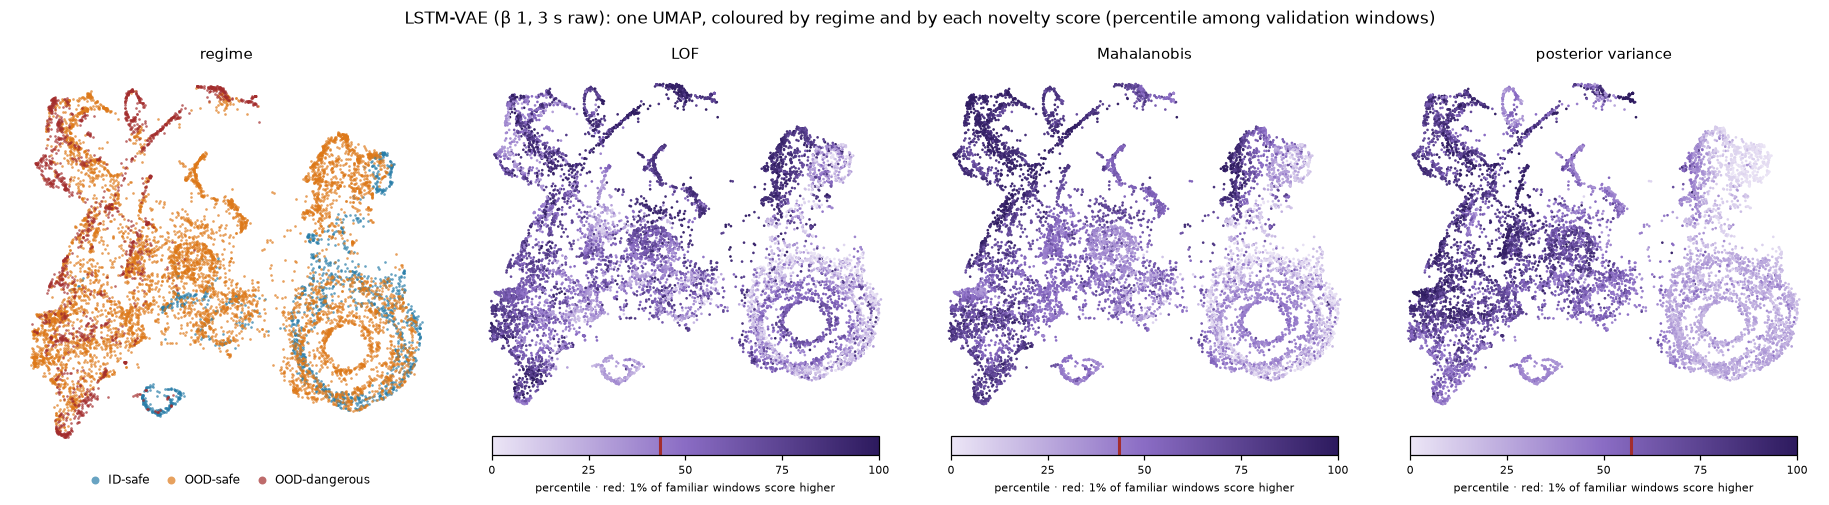

In [3]:
rng = np.random.default_rng(0)
pick = lv.get_balanced_sample(det['labels'], PER_TASK, rng)                     # rows of the validation export
labels = det['labels'].iloc[pick].reset_index(drop = True)
active_det = vr.get_active(det['logvar'], familiar)
views_det = lv.get_views(det['z'][pick][:, active_det], VIEW_CACHE)
print(f'{len(pick):,} windows, {labels.task.nunique()} tasks; LSTM-VAE active dimensions: {int(active_det.sum())} of {det["z"].shape[1]}')
fig = lv.plot_score_panels(views_det[('UMAP', 2)], labels['controller_class'].astype(str).to_numpy(), {k: v[pick] for k, v in pct.items()}, marks,
                           'LSTM-VAE (β 1, 3 s raw): one UMAP, coloured by regime and by each novelty score (percentile among validation windows)',
                           FIG_DIR / '11_lstm_vae_novelty_umap.png')
plt.show()

## 3. The TCN-VAE latent the classifier reads, coloured by regime and task family

The regime classifier's encoder: trained on ID-safe and OOD-safe movement, so OOD-dangerous is the only class it never saw.
Same windows as section 2.

TCN-VAE active dimensions: 11 of 32


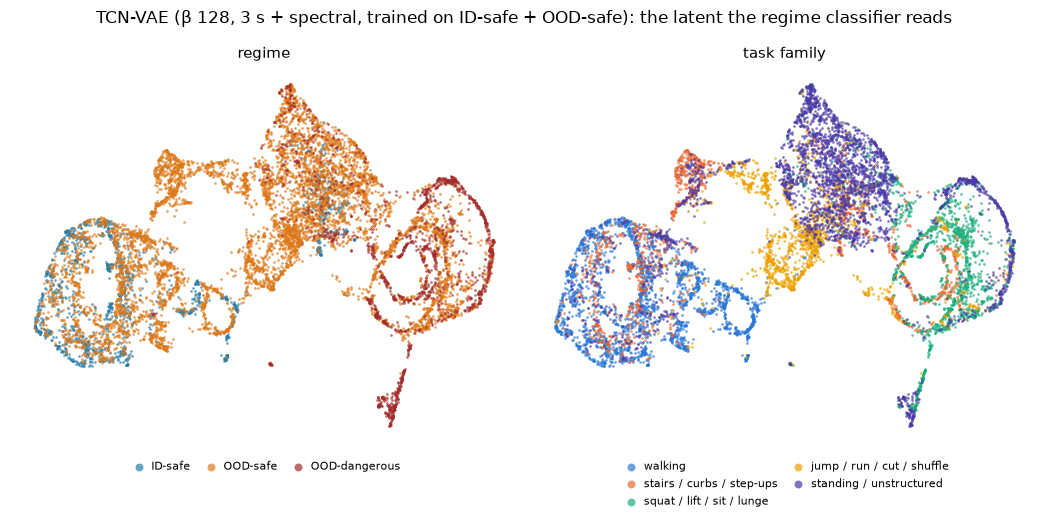

In [4]:
z_enc = lv.get_aligned_z({'labels': enc['labels'], 'z': enc['z']}, labels)
trained_on = np.isin(enc['labels']['controller_class'].astype(str).to_numpy(), ('ID-safe', 'OOD-safe'))
active_enc = vr.get_active(enc['logvar'], trained_on)
views_enc = lv.get_views(z_enc[:, active_enc] if active_enc.sum() >= 3 else z_enc, VIEW_CACHE)
print(f'TCN-VAE active dimensions: {int(active_enc.sum())} of {z_enc.shape[1]}')
pts = views_enc[('UMAP', 2)]
order = np.random.default_rng(0).permutation(len(pts))
fig, axes = plt.subplots(1, 2, figsize = (9.6, 4.8))
for ax, (column, palette, name) in zip(axes, [('controller_class', lv.CLASS_C, 'regime'), ('family', lv.FAMILY_C, 'task family')]):
    values = labels[column].astype(str).to_numpy()[order]
    for lab, color in palette.items():
        m = values == lab
        ax.scatter(pts[order][m, 0], pts[order][m, 1], s = 3, color = color, alpha = .7, linewidths = 0, rasterized = True, label = lab)
    ax.legend(loc = 'upper center', bbox_to_anchor = (.5, -0.02), ncol = 3 if column == 'controller_class' else 2, fontsize = 7.5,
              frameon = False, markerscale = 3, handletextpad = .1, columnspacing = .8)
    ax.set_title(name, fontsize = 10); ax.set_xticks([]); ax.set_yticks([])
    ax.spines[['top', 'right', 'bottom', 'left']].set_visible(False)
fig.suptitle('TCN-VAE (β 128, 3 s + spectral, trained on ID-safe + OOD-safe): the latent the regime classifier reads', fontsize = 11)
fig.tight_layout()
fig.savefig(FIG_DIR / '11_tcn_vae_regime_umap.png', dpi = 180, bbox_inches = 'tight')
plt.show()

## 4. Movable 3-D pages

Both pages show the same windows (a smaller balanced sample, so the pages stay light). The dropdown switches view (latent
units, PCA, UMAP) and lens; hover shows task, participant, direction and, on a score lens, the percentile. Scroll to zoom,
drag to rotate.

In [5]:
pick3 = lv.get_balanced_sample(labels.assign(is_train = False), PER_TASK_3D, np.random.default_rng(1))   # rows of `labels`
lab3 = labels.iloc[pick3].reset_index(drop = True)
for k, v in pct.items():
    lab3[f'{k} percentile'] = v[pick][pick3]
STYLES = lv.get_task_styles(nt.TASK_FAMILIES)
task_lens = ('task', {t: STYLES[t]['family'] for ts in nt.TASK_FAMILIES.values() for t in ts})
symbols = {t: s['symbol'] for t, s in STYLES.items()}

lenses_det = {'regime': ('controller_class', lv.CLASS_C), 'task': task_lens,
              **{f'{k} percentile': (f'{k} percentile', lv.SCORE_SCALE) for k in pct}}
fig_det = lv.build_3d({'LSTM-VAE': {key: v[pick3] for key, v in views_det.items() if key != 'units'}}, lab3, lenses_det, symbols,
                      'LSTM-VAE (β 1, 3 s raw) · validation participants')
fig_det.write_html(INTERACTIVE / '11_lstm_vae_novelty_3d.html', include_plotlyjs = 'cdn', config = CONFIG_3D)

lenses_enc = {'regime': ('controller_class', lv.CLASS_C), 'task': task_lens, 'task family': ('family', lv.FAMILY_C)}
fig_enc = lv.build_3d({'TCN-VAE': {key: v[pick3] for key, v in views_enc.items() if key != 'units'}}, lab3, lenses_enc, symbols,
                      'TCN-VAE (β 128, 3 s + spectral, ID + OOD-safe) · validation participants')
fig_enc.write_html(INTERACTIVE / '11_tcn_vae_regime_3d.html', include_plotlyjs = 'cdn', config = CONFIG_3D)
print(f'{len(lab3):,} windows per page ->', [p.name for p in sorted(INTERACTIVE.glob('11_*.html'))])
fig_det.show(config = CONFIG_3D)

3,120 windows per page -> ['11_lstm_vae_novelty_3d.html', '11_tcn_vae_regime_3d.html']
